In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MASTER_PATH = (
    PROJECT_ROOT / "data" / "processed"
    / "groundwater_master_processed.csv"
)

EDA_DIR = PROJECT_ROOT / "reports" / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)

if not MASTER_PATH.exists():
    raise FileNotFoundError(
        f"Processed master dataset not found: {MASTER_PATH}"
    )

eda_df = pd.read_csv(
    MASTER_PATH,
    dtype=str,
    keep_default_na=False,
    na_filter=False
)

chemical_columns = [
    "Potential of Hydrogen (pH)",
    "Electric Conductivity (μS/cm)",
    "Total Dissolved Solids (mg/L)",
    "Carbonate (mg/L)",
    "Bicarbonate (mg/L)",
    "Total Alkalinity (mg/L as CaCO3)",
    "Chloride (mg/L)",
    "Nitrate N (mgN/L)",
    "Sulphate (mg/L)",
    "Phosphate(mg/L)",
    "Silica(mg/L)",
    "Fluoride (mg/L)",
    "Total Hardness (mgCaCO3/L)",
    "Calcium (mg/L)",
    "Magnesium (mg/L)",
    "Sodium (mg/L)",
    "Potassium (mg/L)",
    "Iron(mg/L)",
    "Arsenic (mg/L)",
    "Uranium(mg/L)",
    "Manganese (mg/L)",
    "Copper (mg/L)",
    "Lead (mg/L)",
    "Zinc (mg/L)",
    "Nickel (mg/L)",
    "Cadmium (mg/L)",
    "Chromium (mg/L)"
]

numeric_columns = ["Latitude", "Longitude"] + chemical_columns

for column in numeric_columns:
    eda_df[column] = pd.to_numeric(
        eda_df[column], errors="coerce"
    )

eda_df["_parsed_date"] = pd.to_datetime(
    eda_df["_parsed_date"],
    errors="coerce"
)

eda_df["_year"] = eda_df["_parsed_date"].dt.year

print("EDA DATASET LOADED")
print("=" * 50)
print("Records:", len(eda_df))
print("Columns:", len(eda_df.columns))
print("Source files:", eda_df["_source_file"].nunique())
print("Date range:",
      eda_df["_parsed_date"].min(),
      "to",
      eda_df["_parsed_date"].max())

EDA DATASET LOADED
Records: 174635
Columns: 199
Source files: 31
Date range: 2000-05-25 00:00:00 to 2025-05-08 10:02:00


In [2]:
overview = pd.DataFrame({
    "Metric": [
        "Total observations",
        "Total columns",
        "Source files",
        "States and UTs",
        "District labels",
        "Provisional station identities",
        "Location candidates",
        "Records with coordinates",
        "Records without coordinates",
        "Valid sampling dates"
    ],
    "Value": [
        len(eda_df),
        len(eda_df.columns),
        eda_df["_source_file"].nunique(),
        eda_df["State"].nunique(),
        eda_df["District"].nunique(),
        eda_df["_provisional_station_id"].nunique(),
        eda_df["_provisional_location_candidate_id"].replace("", np.nan).nunique(),
        (eda_df["Latitude"].notna() & eda_df["Longitude"].notna()).sum(),
        (eda_df["Latitude"].isna() | eda_df["Longitude"].isna()).sum(),
        eda_df["_parsed_date"].notna().sum()
    ]
})

display(overview)

# Historical coverage
year_summary = (
    eda_df.groupby("_year")
    .agg(
        Records=("_year", "size"),
        States=("State", "nunique"),
        Station_Identities=("_provisional_station_id", "nunique")
    )
    .reset_index()
)

print("ANNUAL RECORD DISTRIBUTION")
display(year_summary)

# State-level coverage
state_summary = (
    eda_df.groupby("State")
    .agg(
        Records=("State", "size"),
        Districts=("District", "nunique"),
        Station_Identities=("_provisional_station_id", "nunique")
    )
    .sort_values("Records", ascending=False)
    .reset_index()
)

print("STATE-LEVEL RECORD DISTRIBUTION")
display(state_summary)

,Metric,Value
0,Total observations,174635
1,Total columns,199
2,Source files,31
3,States and UTs,31
4,District labels,596
5,Provisional station identities,23811
6,Location candidates,24172
7,Records with coordinates,174483
8,Records without coordinates,152
9,Valid sampling dates,173625


ANNUAL RECORD DISTRIBUTION


,_year,Records,States,Station_Identities
0,2000.0,6581,27,6569
1,2001.0,5719,23,5703
2,2002.0,6808,24,6791
3,2003.0,6367,25,6357
4,2004.0,7288,24,7279
5,2005.0,6190,30,6184
6,2006.0,6022,28,6015
7,2007.0,6662,28,6656
8,2008.0,6610,27,6596
9,2009.0,7369,30,7363


STATE-LEVEL RECORD DISTRIBUTION


,State,Records,Districts,Station_Identities
0,Madhya Pradesh,19230,51,1702
1,Maharashtra,18249,35,1850
2,Odisha,15400,30,1942
3,Karnataka,13007,27,2033
4,Rajasthan,12350,34,1607
5,Andhra Pradesh,10950,14,1540
6,Chhattisgarh,10350,23,1291
7,Gujarat,9807,28,966
8,Kerala,9473,15,1059
9,Tamil Nadu,8419,33,1214


,Parameter,Available_Values,Missing_Values,Availability_Percentage
0,Electric Conductivity (μS/cm),173029,1606,99.08
1,Potential of Hydrogen (pH),162729,11906,93.18
2,Chloride (mg/L),162034,12601,92.78
3,Magnesium (mg/L),150422,24213,86.14
4,Calcium (mg/L),149855,24780,85.81
5,Bicarbonate (mg/L),147171,27464,84.27
6,Total Hardness (mgCaCO3/L),144408,30227,82.69
7,Sodium (mg/L),143470,31165,82.15
8,Sulphate (mg/L),126328,48307,72.34
9,Carbonate (mg/L),120229,54406,68.85


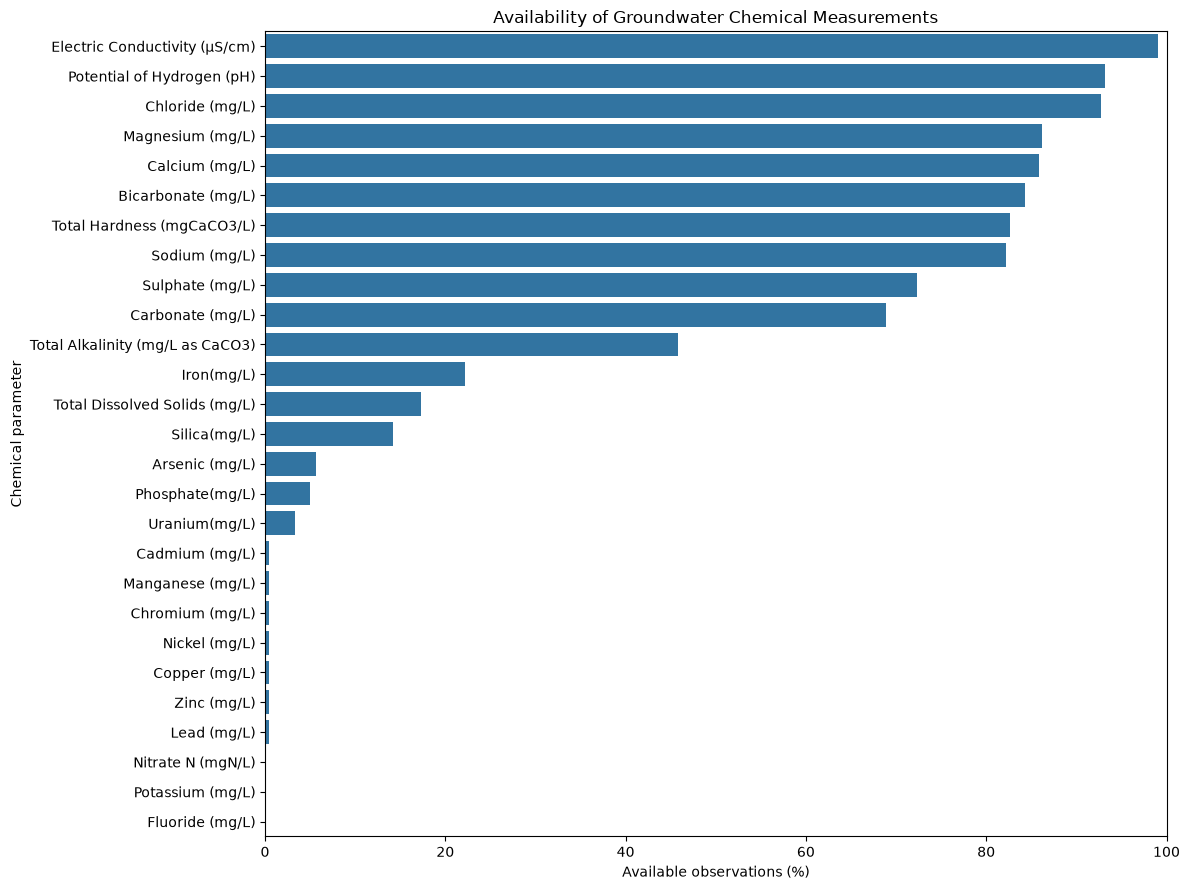

In [3]:
availability_summary = pd.DataFrame({
    "Parameter": chemical_columns,
    "Available_Values": [
        eda_df[column].notna().sum()
        for column in chemical_columns
    ],
    "Missing_Values": [
        eda_df[column].isna().sum()
        for column in chemical_columns
    ],
    "Availability_Percentage": [
        round(eda_df[column].notna().mean() * 100, 2)
        for column in chemical_columns
    ]
})

availability_summary = availability_summary.sort_values(
    "Availability_Percentage",
    ascending=False
).reset_index(drop=True)

display(availability_summary)

plt.figure(figsize=(12, 9))

sns.barplot(
    data=availability_summary,
    x="Availability_Percentage",
    y="Parameter"
)

plt.title("Availability of Groundwater Chemical Measurements")
plt.xlabel("Available observations (%)")
plt.ylabel("Chemical parameter")
plt.xlim(0, 100)
plt.tight_layout()

plt.savefig(
    EDA_DIR / "01_chemical_parameter_availability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

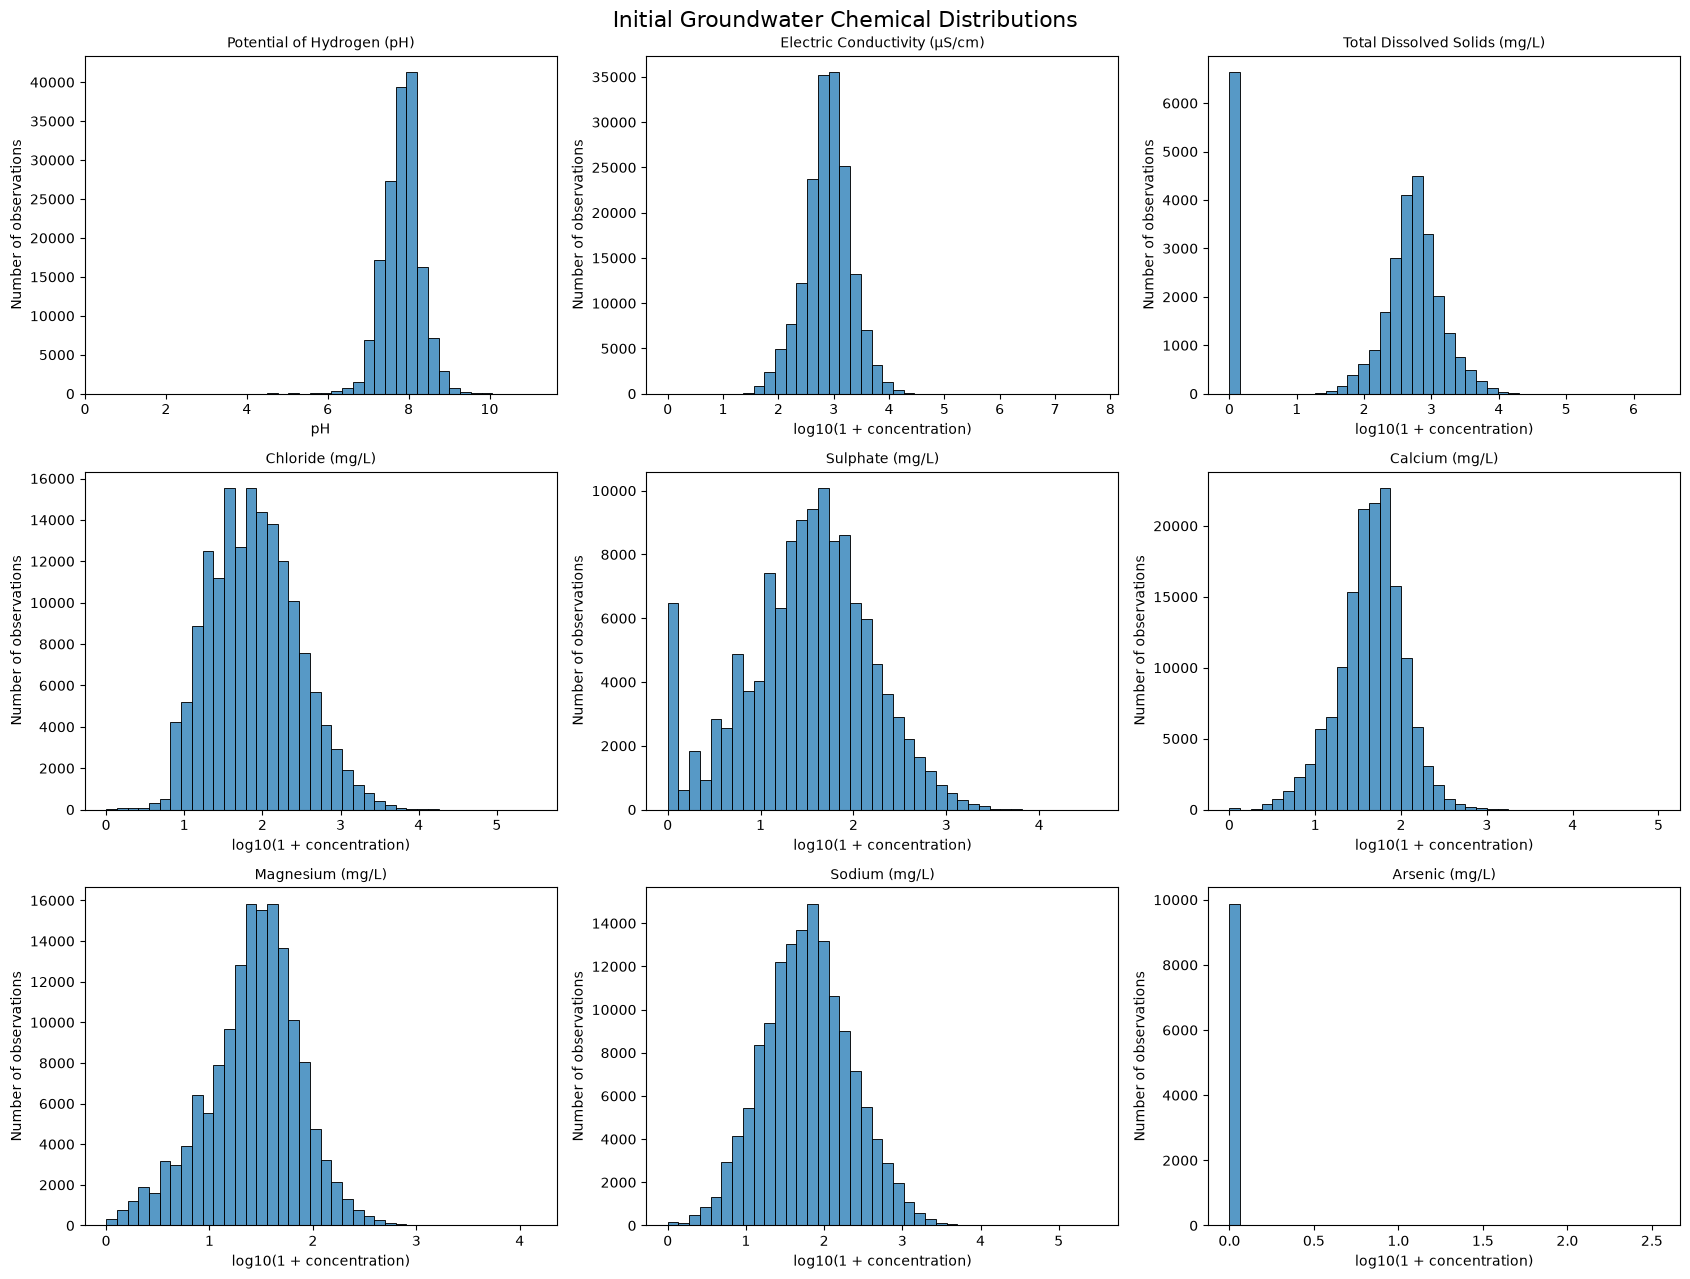

,Parameter,Original_Available,Included_In_Plot,Excluded_From_Plot,Display_Transformation
0,Potential of Hydrogen (pH),162729,162719,10,Original pH scale
1,Electric Conductivity (μS/cm),173029,173029,0,Log10(1 + value)
2,Total Dissolved Solids (mg/L),30151,30151,0,Log10(1 + value)
3,Chloride (mg/L),162034,162033,1,Log10(1 + value)
4,Sulphate (mg/L),126328,126326,2,Log10(1 + value)
5,Calcium (mg/L),149855,149855,0,Log10(1 + value)
6,Magnesium (mg/L),150422,150412,10,Log10(1 + value)
7,Sodium (mg/L),143470,143470,0,Log10(1 + value)
8,Arsenic (mg/L),9927,9927,0,Log10(1 + value)


In [4]:
selected_parameters = [
    "Potential of Hydrogen (pH)",
    "Electric Conductivity (μS/cm)",
    "Total Dissolved Solids (mg/L)",
    "Chloride (mg/L)",
    "Sulphate (mg/L)",
    "Calcium (mg/L)",
    "Magnesium (mg/L)",
    "Sodium (mg/L)",
    "Arsenic (mg/L)"
]

fig, axes = plt.subplots(3, 3, figsize=(17, 13))

distribution_report = []

for column, ax in zip(selected_parameters, axes.flatten()):

    values = eda_df[column].dropna()

    if column == "Potential of Hydrogen (pH)":
        screened = values[(values > 0) & (values <= 14)]
        plotted_values = screened
        x_label = "pH"
        transformation = "Original pH scale"

    else:
        screened = values[values >= 0]
        plotted_values = np.log10(screened + 1)
        x_label = "log10(1 + concentration)"
        transformation = "Log10(1 + value)"

    if len(plotted_values) > 0:

        sns.histplot(
            plotted_values,
            bins=40,
            ax=ax
        )

        ax.set_title(column, fontsize=10)
        ax.set_xlabel(x_label)
        ax.set_ylabel("Number of observations")

    else:
        ax.set_title(f"{column} — No available data")
        ax.set_axis_off()

    distribution_report.append({
        "Parameter": column,
        "Original_Available": len(values),
        "Included_In_Plot": len(screened),
        "Excluded_From_Plot": len(values) - len(screened),
        "Display_Transformation": transformation
    })

plt.suptitle(
    "Initial Groundwater Chemical Distributions",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    EDA_DIR / "02_initial_chemical_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

distribution_report_df = pd.DataFrame(distribution_report)

display(distribution_report_df)

In [5]:
# Investigate records missing from the annual EDA grouping

print("DATE CONSISTENCY CHECK")
print("=" * 50)

print("Total master records:", len(eda_df))
print("Records with parsed dates:",
      eda_df["_parsed_date"].notna().sum())
print("Records missing parsed dates:",
      eda_df["_parsed_date"].isna().sum())
print("Records included in annual summary:",
      year_summary["Records"].sum())

# Compare parsed dates against the original sampling-date column
fallback_dates = pd.to_datetime(
    eda_df["Data Acquisition Time"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

print("\nFALLBACK DATE PARSING")
print("Successfully parsed original dates:",
      fallback_dates.notna().sum())
print("Original dates still invalid:",
      fallback_dates.isna().sum())

# Examine records whose parsed date is missing
missing_date_rows = eda_df[
    eda_df["_parsed_date"].isna()
]

print("\nMISSING PARSED DATE EXAMPLES")

display(
    missing_date_rows[
        [
            "Station",
            "State",
            "District",
            "Data Acquisition Time",
            "_parsed_date",
            "_source_file",
            "_source_row"
        ]
    ].head(20)
)

# Check how many missing parsed dates can be recovered
recoverable = (
    eda_df["_parsed_date"].isna()
    & fallback_dates.notna()
)

print("\nRecoverable date records:", recoverable.sum())

DATE CONSISTENCY CHECK
Total master records: 174635
Records with parsed dates: 173625
Records missing parsed dates: 1010
Records included in annual summary: 173625

FALLBACK DATE PARSING
Successfully parsed original dates: 174635
Original dates still invalid: 0

MISSING PARSED DATE EXAMPLES


,Station,State,District,Data Acquisition Time,_parsed_date,_source_file,_source_row
162105,Gajraula Q,Uttar Pradesh,JYOTIBA PHULE NAGAR,25-05-2012 00:00,NaT,gwq_chemical_parameter_manual_cgwb_up_1961_2025,2369
162106,Gajraula Q,Uttar Pradesh,JYOTIBA PHULE NAGAR,25-05-2013 00:00,NaT,gwq_chemical_parameter_manual_cgwb_up_1961_2025,2370
162107,Gajraula Q,Uttar Pradesh,JYOTIBA PHULE NAGAR,25-05-2014 00:00,NaT,gwq_chemical_parameter_manual_cgwb_up_1961_2025,2371
162108,Gajraula Q,Uttar Pradesh,JYOTIBA PHULE NAGAR,25-05-2015 00:00,NaT,gwq_chemical_parameter_manual_cgwb_up_1961_2025,2372
162109,Ganeshganjbazar,Uttar Pradesh,JAUNPUR,25-05-2003 00:00,NaT,gwq_chemical_parameter_manual_cgwb_up_1961_2025,2373
162110,Gangaganj,Uttar Pradesh,LUCKNOW,25-05-2003 00:00,NaT,gwq_chemical_parameter_manual_cgwb_up_1961_2025,2374
162111,Gangaganj,Uttar Pradesh,LUCKNOW,25-05-2016 00:00,NaT,gwq_chemical_parameter_manual_cgwb_up_1961_2025,2375
162112,Gangaganj,Uttar Pradesh,LUCKNOW,25-05-2018 00:00,NaT,gwq_chemical_parameter_manual_cgwb_up_1961_2025,2376
162113,Gangapur Basai,Uttar Pradesh,AGRA,25-05-2003 00:00,NaT,gwq_chemical_parameter_manual_cgwb_up_1961_2025,2377
162114,Gangapur Basai,Uttar Pradesh,AGRA,25-05-2005 00:00,NaT,gwq_chemical_parameter_manual_cgwb_up_1961_2025,2378



Recoverable date records: 1010


In [6]:
# Re-parse dates directly from the original sampling-date column

eda_df["_parsed_date"] = pd.to_datetime(
    eda_df["Data Acquisition Time"].astype(str).str.strip(),
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

# Rebuild the year column
eda_df["_year"] = eda_df["_parsed_date"].dt.year

# Recalculate annual distribution
year_summary = (
    eda_df.groupby("_year")
    .agg(
        Records=("_year", "size"),
        States=("State", "nunique"),
        Station_Identities=("_provisional_station_id", "nunique")
    )
    .reset_index()
)

print("CORRECTED DATE VALIDATION")
print("=" * 50)

print("Total records:", len(eda_df))
print("Successfully parsed dates:", eda_df["_parsed_date"].notna().sum())
print("Invalid dates:", eda_df["_parsed_date"].isna().sum())
print("Records in annual summary:", year_summary["Records"].sum())

print("\nCORRECTED DATE RANGE")
print("Earliest:", eda_df["_parsed_date"].min())
print("Latest:", eda_df["_parsed_date"].max())

print("\nCORRECTED ANNUAL DISTRIBUTION")
display(year_summary)

assert eda_df["_parsed_date"].notna().all()
assert year_summary["Records"].sum() == 174635

print("\nAll date consistency checks passed.")

CORRECTED DATE VALIDATION
Total records: 174635
Successfully parsed dates: 174635
Invalid dates: 0
Records in annual summary: 174635

CORRECTED DATE RANGE
Earliest: 2000-05-25 00:00:00
Latest: 2025-05-08 10:02:00

CORRECTED ANNUAL DISTRIBUTION


,_year,Records,States,Station_Identities
0,2000,6645,27,6633
1,2001,5747,23,5731
2,2002,6862,24,6845
3,2003,6486,25,6475
4,2004,7332,24,7323
5,2005,6215,30,6209
6,2006,6022,28,6015
7,2007,6662,28,6656
8,2008,6649,27,6635
9,2009,7440,30,7434



All date consistency checks passed.


In [7]:
core_parameters = [
    "Potential of Hydrogen (pH)",
    "Electric Conductivity (μS/cm)",
    "Chloride (mg/L)",
    "Calcium (mg/L)",
    "Magnesium (mg/L)",
    "Sodium (mg/L)",
    "Bicarbonate (mg/L)",
    "Sulphate (mg/L)",
    "Total Hardness (mgCaCO3/L)"
]

analysis_values = pd.DataFrame(index=eda_df.index)

screening_results = []

for column in core_parameters:

    values = eda_df[column].replace(
        [np.inf, -np.inf], np.nan
    )

    if column == "Potential of Hydrogen (pH)":
        valid_mask = values.between(0, 14, inclusive="neither")
    else:
        valid_mask = values.ge(0)

    analysis_values[column] = values.where(valid_mask)

    screening_results.append({
        "Parameter": column,
        "Original_Available": int(values.notna().sum()),
        "Included_In_Analysis": int(valid_mask.sum()),
        "Negative_Values": int(values.lt(0).sum()),
        "Zero_Values": int(values.eq(0).sum()),
        "Excluded_By_Screening": int(
            (values.notna() & ~valid_mask).sum()
        )
    })

screening_summary = pd.DataFrame(screening_results)

print("CORE CHEMICAL PARAMETER SCREENING")
display(screening_summary)

CORE CHEMICAL PARAMETER SCREENING


,Parameter,Original_Available,Included_In_Analysis,Negative_Values,Zero_Values,Excluded_By_Screening
0,Potential of Hydrogen (pH),162729,162719,0,4,10
1,Electric Conductivity (μS/cm),173029,173029,0,2,0
2,Chloride (mg/L),162034,162033,1,10,1
3,Calcium (mg/L),149855,149855,0,76,0
4,Magnesium (mg/L),150422,150412,10,162,10
5,Sodium (mg/L),143470,143470,0,108,0
6,Bicarbonate (mg/L),147171,147170,1,739,1
7,Sulphate (mg/L),126328,126326,2,5806,2
8,Total Hardness (mgCaCO3/L),144408,144408,0,151,0


In [8]:
# Primary groundwater chemistry parameters
analysis_parameters = [
    "Potential of Hydrogen (pH)",
    "Electric Conductivity (μS/cm)",
    "Total Dissolved Solids (mg/L)",
    "Chloride (mg/L)",
    "Bicarbonate (mg/L)",
    "Sulphate (mg/L)",
    "Calcium (mg/L)",
    "Magnesium (mg/L)",
    "Sodium (mg/L)",
    "Total Hardness (mgCaCO3/L)",
    "Carbonate (mg/L)",
    "Total Alkalinity (mg/L as CaCO3)"
]

descriptive_results = []

for column in analysis_parameters:

    values = eda_df[column].dropna()

    if column == "Potential of Hydrogen (pH)":
        values = values[(values > 0) & (values <= 14)]
    else:
        values = values[
            np.isfinite(values) & (values >= 0)
        ]

    descriptive_results.append({
        "Parameter": column,
        "Valid_Observations": len(values),
        "Mean": values.mean(),
        "Median": values.median(),
        "Std_Dev": values.std(),
        "Q1": values.quantile(0.25),
        "Q3": values.quantile(0.75),
        "P95": values.quantile(0.95),
        "P99": values.quantile(0.99),
        "Minimum": values.min(),
        "Maximum": values.max()
    })

descriptive_stats_df = pd.DataFrame(descriptive_results)

display(
    descriptive_stats_df.round(3)
)

,Parameter,Valid_Observations,Mean,Median,Std_Dev,Q1,Q3,P95,P99,Minimum,Maximum
0,Potential of Hydrogen (pH),162719,7.843,7.87,0.470,7.56,8.12,8.560,8.97,0.52,1.113000e+01
1,Electric Conductivity (μS/cm),173029,1902.079,801.00,153432.478,450.00,1408.00,3690.000,7727.20,0.00,5.700676e+07
2,Total Dissolved Solids (mg/L),30151,766.206,421.00,13598.176,96.00,793.00,2404.175,5586.00,0.00,2.353897e+06
3,Chloride (mg/L),162033,197.504,72.00,1066.131,28.00,185.00,732.000,1953.00,0.00,3.094720e+05
4,Bicarbonate (mg/L),147170,301.275,256.00,2736.508,157.00,378.00,622.000,915.00,0.00,8.178300e+05
5,Sulphate (mg/L),126326,95.499,35.00,261.653,11.00,89.00,379.000,990.00,0.00,4.185500e+04
6,Calcium (mg/L),149855,63.273,46.00,274.727,26.00,76.00,164.000,320.00,0.00,1.001660e+05
7,Magnesium (mg/L),150412,42.301,28.00,68.437,13.42,51.00,124.239,260.00,0.00,1.411700e+04
8,Sodium (mg/L),143470,145.116,59.00,1048.220,24.00,140.00,546.000,1270.00,0.00,3.075940e+05
9,Total Hardness (mgCaCO3/L),144408,334.655,250.00,1723.957,150.00,390.00,845.000,1700.00,0.00,5.256350e+05


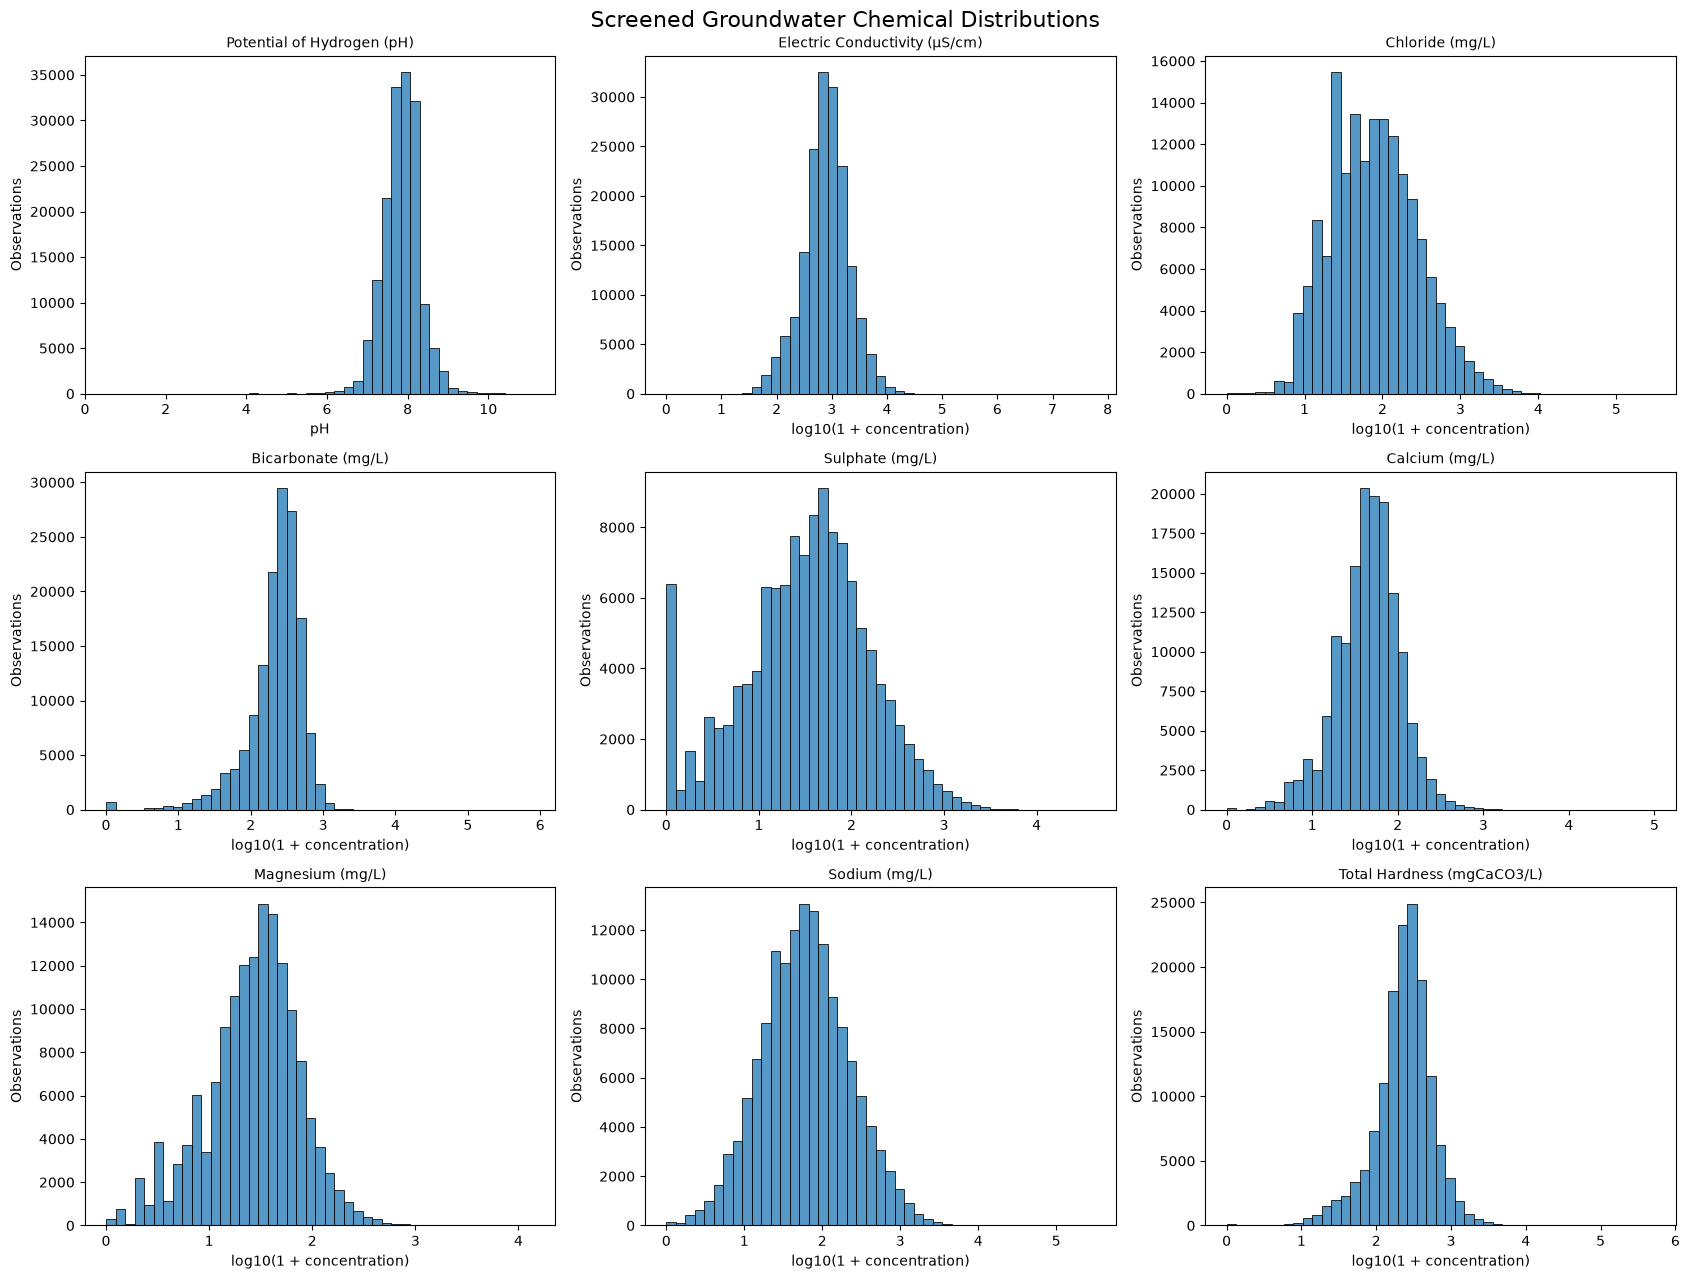

In [9]:
distribution_parameters = [
    "Potential of Hydrogen (pH)",
    "Electric Conductivity (μS/cm)",
    "Chloride (mg/L)",
    "Bicarbonate (mg/L)",
    "Sulphate (mg/L)",
    "Calcium (mg/L)",
    "Magnesium (mg/L)",
    "Sodium (mg/L)",
    "Total Hardness (mgCaCO3/L)"
]

fig, axes = plt.subplots(3, 3, figsize=(17, 13))

for column, ax in zip(
    distribution_parameters,
    axes.flatten()
):

    values = eda_df[column].dropna()

    if column == "Potential of Hydrogen (pH)":
        values = values[(values > 0) & (values <= 14)]
        plotted_values = values
        xlabel = "pH"

    else:
        values = values[
            np.isfinite(values) & (values >= 0)
        ]
        plotted_values = np.log10(1 + values)
        xlabel = "log10(1 + concentration)"

    sns.histplot(
        plotted_values,
        bins=45,
        ax=ax
    )

    ax.set_title(column, fontsize=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Observations")

plt.suptitle(
    "Screened Groundwater Chemical Distributions",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    EDA_DIR / "03_screened_chemical_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

SPEARMAN CORRELATION MATRIX


,Potential of Hydrogen (pH),Electric Conductivity (μS/cm),Total Dissolved Solids (mg/L),Chloride (mg/L),Bicarbonate (mg/L),Sulphate (mg/L),Calcium (mg/L),Magnesium (mg/L),Sodium (mg/L),Total Hardness (mgCaCO3/L),Carbonate (mg/L),Total Alkalinity (mg/L as CaCO3)
Potential of Hydrogen (pH),1.00,0.04,0.14,0.03,0.02,0.08,-0.20,0.06,0.14,-0.08,0.56,0.12
Electric Conductivity (μS/cm),0.04,1.00,0.55,0.88,0.70,0.75,0.63,0.79,0.87,0.84,0.04,0.64
Total Dissolved Solids (mg/L),0.14,0.55,1.00,0.52,0.42,0.46,0.36,0.43,0.54,0.46,0.01,0.58
Chloride (mg/L),0.03,0.88,0.52,1.00,0.45,0.69,0.55,0.68,0.80,0.73,0.03,0.44
Bicarbonate (mg/L),0.02,0.70,0.42,0.45,1.00,0.39,0.43,0.60,0.62,0.62,-0.08,0.90
Sulphate (mg/L),0.08,0.75,0.46,0.69,0.39,1.00,0.44,0.61,0.69,0.63,0.08,0.39
Calcium (mg/L),-0.20,0.63,0.36,0.55,0.43,0.44,1.00,0.48,0.36,0.80,-0.22,0.31
Magnesium (mg/L),0.06,0.79,0.43,0.68,0.60,0.61,0.48,1.00,0.58,0.87,0.01,0.53
Sodium (mg/L),0.14,0.87,0.54,0.80,0.62,0.69,0.36,0.58,1.00,0.56,0.13,0.61
Total Hardness (mgCaCO3/L),-0.08,0.84,0.46,0.73,0.62,0.63,0.80,0.87,0.56,1.00,-0.11,0.51



PAIRED OBSERVATION COUNTS


,Potential of Hydrogen (pH),Electric Conductivity (μS/cm),Total Dissolved Solids (mg/L),Chloride (mg/L),Bicarbonate (mg/L),Sulphate (mg/L),Calcium (mg/L),Magnesium (mg/L),Sodium (mg/L),Total Hardness (mgCaCO3/L),Carbonate (mg/L),Total Alkalinity (mg/L as CaCO3)
Potential of Hydrogen (pH),162719,162694,30108,156792,146454,125822,147995,148597,142654,141784,119737,79844
Electric Conductivity (μS/cm),162694,173029,30142,161997,147140,126297,149819,150378,143439,144385,120193,79916
Total Dissolved Solids (mg/L),30108,30142,30151,30130,29509,26048,29599,29596,29578,29546,27650,11584
Chloride (mg/L),156792,161997,30130,162033,144697,124888,148159,147968,142685,141105,117480,78486
Bicarbonate (mg/L),146454,147140,29509,144697,147170,125836,145802,145696,142756,138802,119532,79899
Sulphate (mg/L),125822,126297,26048,124888,125836,126326,126141,126080,123842,124828,107091,77383
Calcium (mg/L),147995,149819,29599,148159,145802,126141,149855,149586,143160,141885,118423,78827
Magnesium (mg/L),148597,150378,29596,147968,145696,126080,149586,150412,143108,142470,118362,78832
Sodium (mg/L),142654,143439,29578,142685,142756,123842,143160,143108,143470,135463,115639,77441
Total Hardness (mgCaCO3/L),141784,144385,29546,141105,138802,124828,141885,142470,135463,144408,118078,79495


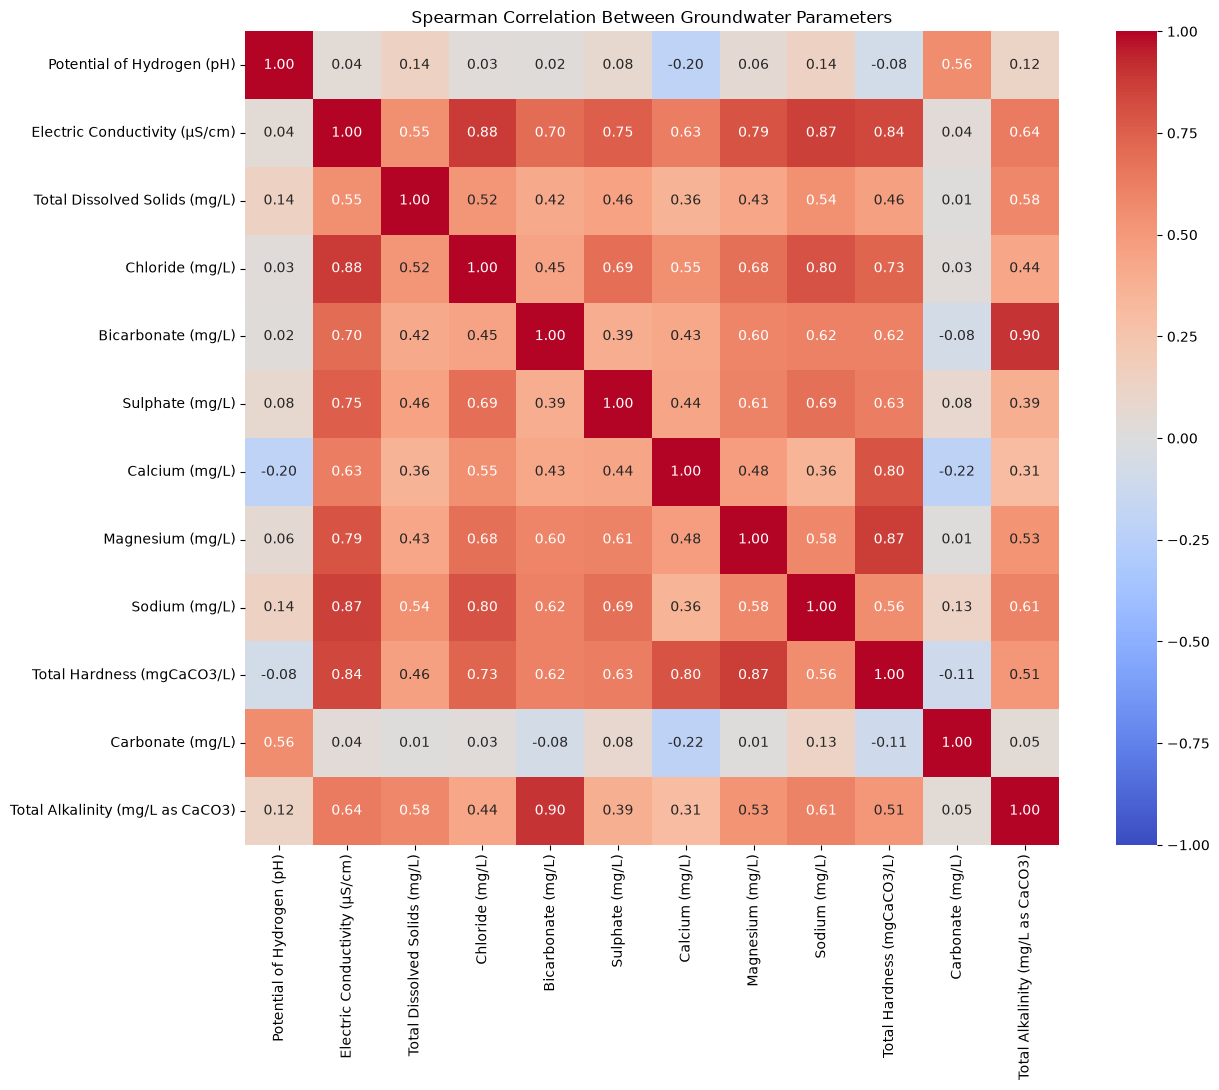

In [10]:
correlation_parameters = [
    "Potential of Hydrogen (pH)",
    "Electric Conductivity (μS/cm)",
    "Total Dissolved Solids (mg/L)",
    "Chloride (mg/L)",
    "Bicarbonate (mg/L)",
    "Sulphate (mg/L)",
    "Calcium (mg/L)",
    "Magnesium (mg/L)",
    "Sodium (mg/L)",
    "Total Hardness (mgCaCO3/L)",
    "Carbonate (mg/L)",
    "Total Alkalinity (mg/L as CaCO3)"
]

corr_data = eda_df[correlation_parameters].copy()

# Screen invalid observations for statistical analysis only.
for column in correlation_parameters:

    if column == "Potential of Hydrogen (pH)":
        corr_data.loc[
            ~corr_data[column].between(0.000001, 14),
            column
        ] = np.nan

    else:
        corr_data.loc[
            (corr_data[column] < 0)
            | (~np.isfinite(corr_data[column])),
            column
        ] = np.nan

# Pairwise observation counts
pair_counts = (
    corr_data.notna().astype(int).T
    .dot(corr_data.notna().astype(int))
)

# Spearman correlation matrix
spearman_corr = corr_data.corr(
    method="spearman",
    min_periods=1000
)

print("SPEARMAN CORRELATION MATRIX")
display(spearman_corr.round(2))

print("\nPAIRED OBSERVATION COUNTS")
display(pair_counts)

plt.figure(figsize=(14, 11))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Spearman Correlation Between Groundwater Parameters")
plt.tight_layout()

plt.savefig(
    EDA_DIR / "04_spearman_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

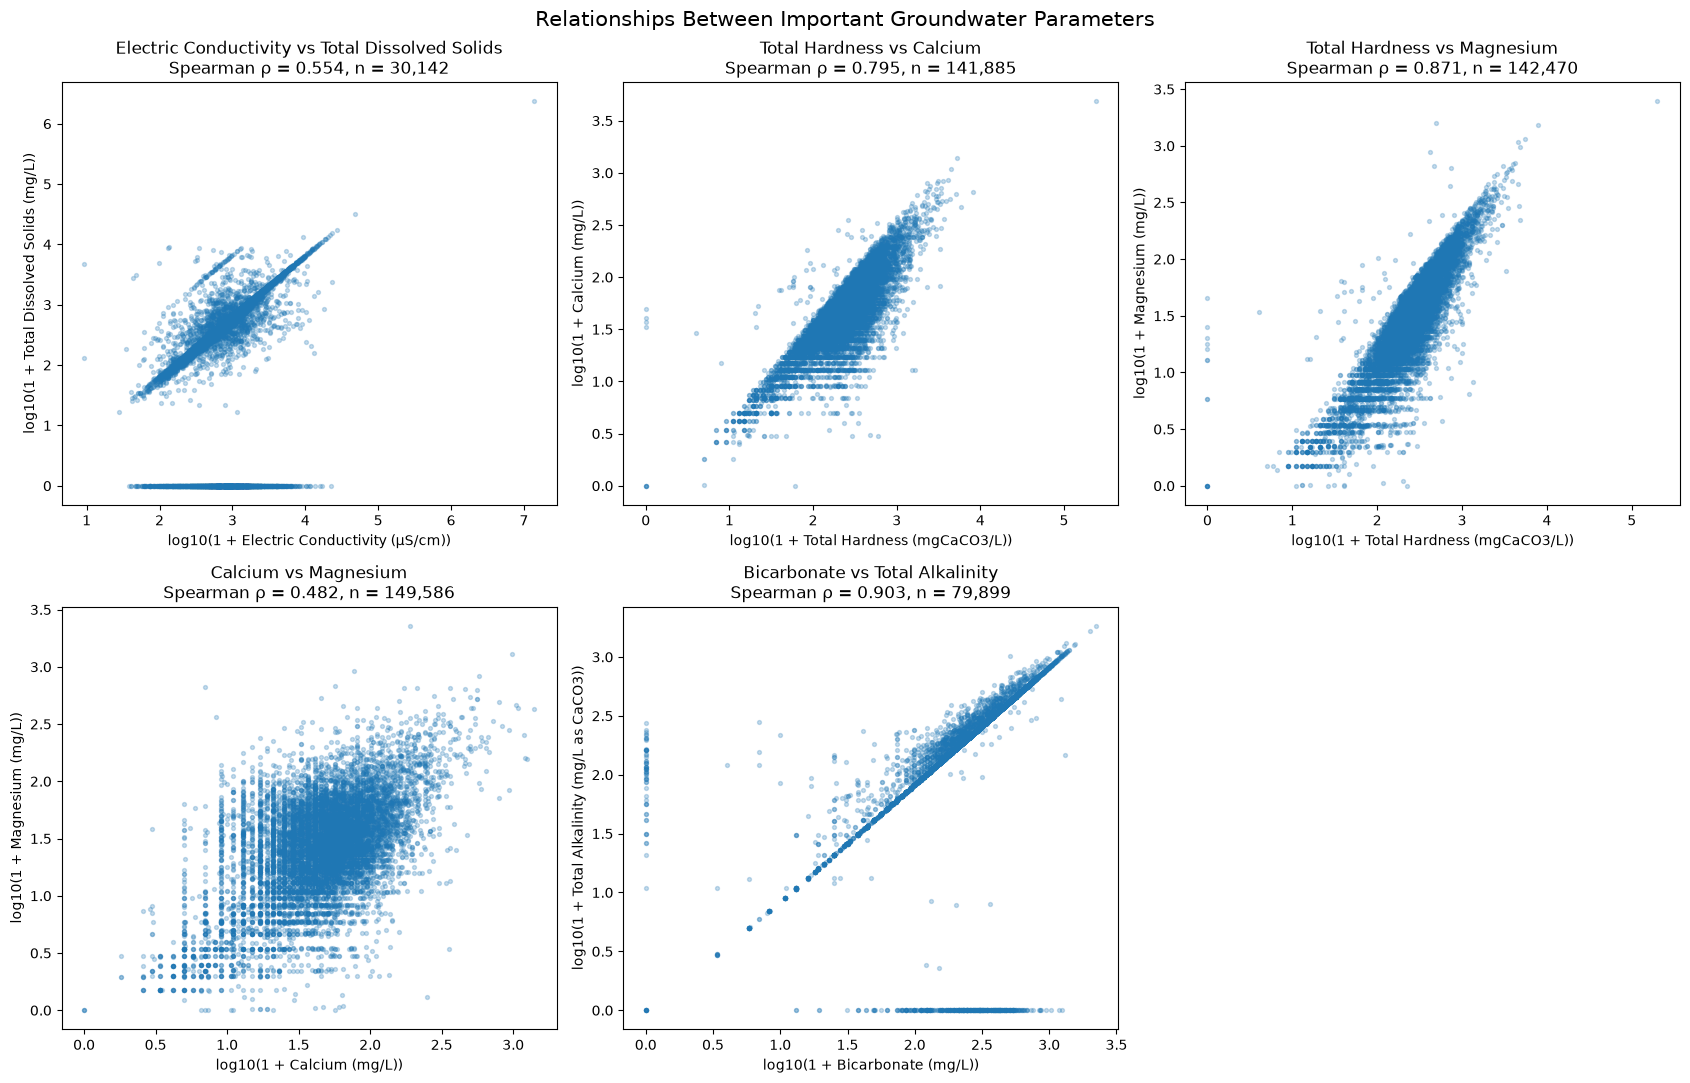

,X_Parameter,Y_Parameter,Paired_Observations,Spearman_Correlation
0,Electric Conductivity (μS/cm),Total Dissolved Solids (mg/L),30142,0.554
1,Total Hardness (mgCaCO3/L),Calcium (mg/L),141885,0.795
2,Total Hardness (mgCaCO3/L),Magnesium (mg/L),142470,0.871
3,Calcium (mg/L),Magnesium (mg/L),149586,0.482
4,Bicarbonate (mg/L),Total Alkalinity (mg/L as CaCO3),79899,0.903


In [11]:
relationship_pairs = [
    ("Electric Conductivity (μS/cm)",
     "Total Dissolved Solids (mg/L)"),

    ("Total Hardness (mgCaCO3/L)",
     "Calcium (mg/L)"),

    ("Total Hardness (mgCaCO3/L)",
     "Magnesium (mg/L)"),

    ("Calcium (mg/L)",
     "Magnesium (mg/L)"),

    ("Bicarbonate (mg/L)",
     "Total Alkalinity (mg/L as CaCO3)")
]

relationship_results = []

fig, axes = plt.subplots(2, 3, figsize=(17, 11))
axes = axes.flatten()

for i, (x_col, y_col) in enumerate(relationship_pairs):

    pair = eda_df[[x_col, y_col]].dropna().copy()

    pair = pair[
        np.isfinite(pair[x_col])
        & np.isfinite(pair[y_col])
        & (pair[x_col] >= 0)
        & (pair[y_col] >= 0)
    ]

    if len(pair) < 3:
        axes[i].set_title("Insufficient paired observations")
        continue

    rho = pair.corr(
        method="spearman"
    ).iloc[0, 1]

    relationship_results.append({
        "X_Parameter": x_col,
        "Y_Parameter": y_col,
        "Paired_Observations": len(pair),
        "Spearman_Correlation": rho
    })

    # Log transformation is for visualization only.
    plotted_pair = pd.DataFrame({
        "X": np.log10(1 + pair[x_col]),
        "Y": np.log10(1 + pair[y_col])
    })

    plotted_pair = plotted_pair.sample(
        n=min(10000, len(plotted_pair)),
        random_state=42
    )

    axes[i].scatter(
        plotted_pair["X"],
        plotted_pair["Y"],
        s=8,
        alpha=0.25
    )

    axes[i].set_title(
        f"{x_col.split(' (')[0]} vs "
        f"{y_col.split(' (')[0]}\n"
        f"Spearman ρ = {rho:.3f}, n = {len(pair):,}"
    )

    axes[i].set_xlabel(f"log10(1 + {x_col})")
    axes[i].set_ylabel(f"log10(1 + {y_col})")

axes[-1].set_axis_off()

plt.suptitle(
    "Relationships Between Important Groundwater Parameters",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    EDA_DIR / "05_chemical_relationships.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

relationship_summary_df = pd.DataFrame(
    relationship_results
)

display(relationship_summary_df.round(3))

In [12]:
state_parameters = [
    "Potential of Hydrogen (pH)",
    "Electric Conductivity (μS/cm)",
    "Chloride (mg/L)",
    "Bicarbonate (mg/L)",
    "Sulphate (mg/L)",
    "Calcium (mg/L)",
    "Magnesium (mg/L)",
    "Sodium (mg/L)"
]

state_medians = (
    eda_df.groupby("State")[state_parameters]
    .median()
)

state_counts = (
    eda_df.groupby("State")[state_parameters]
    .count()
)

print("STATE-WISE CHEMICAL MEDIANS")
display(state_medians.round(2))

print("\nSTATE-WISE AVAILABLE OBSERVATIONS")
display(state_counts)

# Save both summaries
state_medians.to_csv(
    EDA_DIR / "06_statewise_chemical_medians.csv"
)

state_counts.to_csv(
    EDA_DIR / "07_statewise_chemical_counts.csv"
)

STATE-WISE CHEMICAL MEDIANS


,Potential of Hydrogen (pH),Electric Conductivity (μS/cm),Chloride (mg/L),Bicarbonate (mg/L),Sulphate (mg/L),Calcium (mg/L),Magnesium (mg/L),Sodium (mg/L)
State,,,,,,,,
Andaman And Nicobar Islands,7.96,516.00,38.00,214.00,21.00,32.00,21.94,33.00
Andhra Pradesh,7.91,1296.50,160.00,329.00,62.00,56.00,40.00,130.00
Arunachal Pradesh,7.67,160.15,28.36,48.00,6.41,13.20,6.07,12.35
Assam,7.86,307.45,40.00,96.00,11.60,24.35,10.73,23.32
Bihar,8.00,650.00,48.70,250.10,19.00,36.00,27.60,42.00
Chandigarh,8.00,665.00,51.00,216.00,43.50,34.00,23.40,51.50
Chhattisgarh,7.82,461.00,35.00,155.00,16.00,40.00,14.00,25.00
Dadra And Nagar Haveli,7.80,482.00,28.00,183.00,12.00,41.92,19.00,15.00
Delhi,8.09,1634.50,238.50,270.00,144.00,59.00,52.30,216.85



STATE-WISE AVAILABLE OBSERVATIONS


,Potential of Hydrogen (pH),Electric Conductivity (μS/cm),Chloride (mg/L),Bicarbonate (mg/L),Sulphate (mg/L),Calcium (mg/L),Magnesium (mg/L),Sodium (mg/L)
State,,,,,,,,
Andaman And Nicobar Islands,634,634,633,633,529,633,633,633
Andhra Pradesh,10839,10938,10632,9858,8565,9791,9857,9686
Arunachal Pradesh,104,104,47,103,92,104,104,66
Assam,1862,1858,823,1848,1621,1848,1849,1054
Bihar,2807,3112,2915,2930,945,2937,2939,2893
Chandigarh,32,36,35,28,28,32,32,32
Chhattisgarh,9895,10233,9708,9719,8420,9714,9731,8902
Dadra And Nagar Haveli,161,169,149,155,149,149,149,149
Delhi,1099,1166,1168,1014,1018,1094,1094,1095


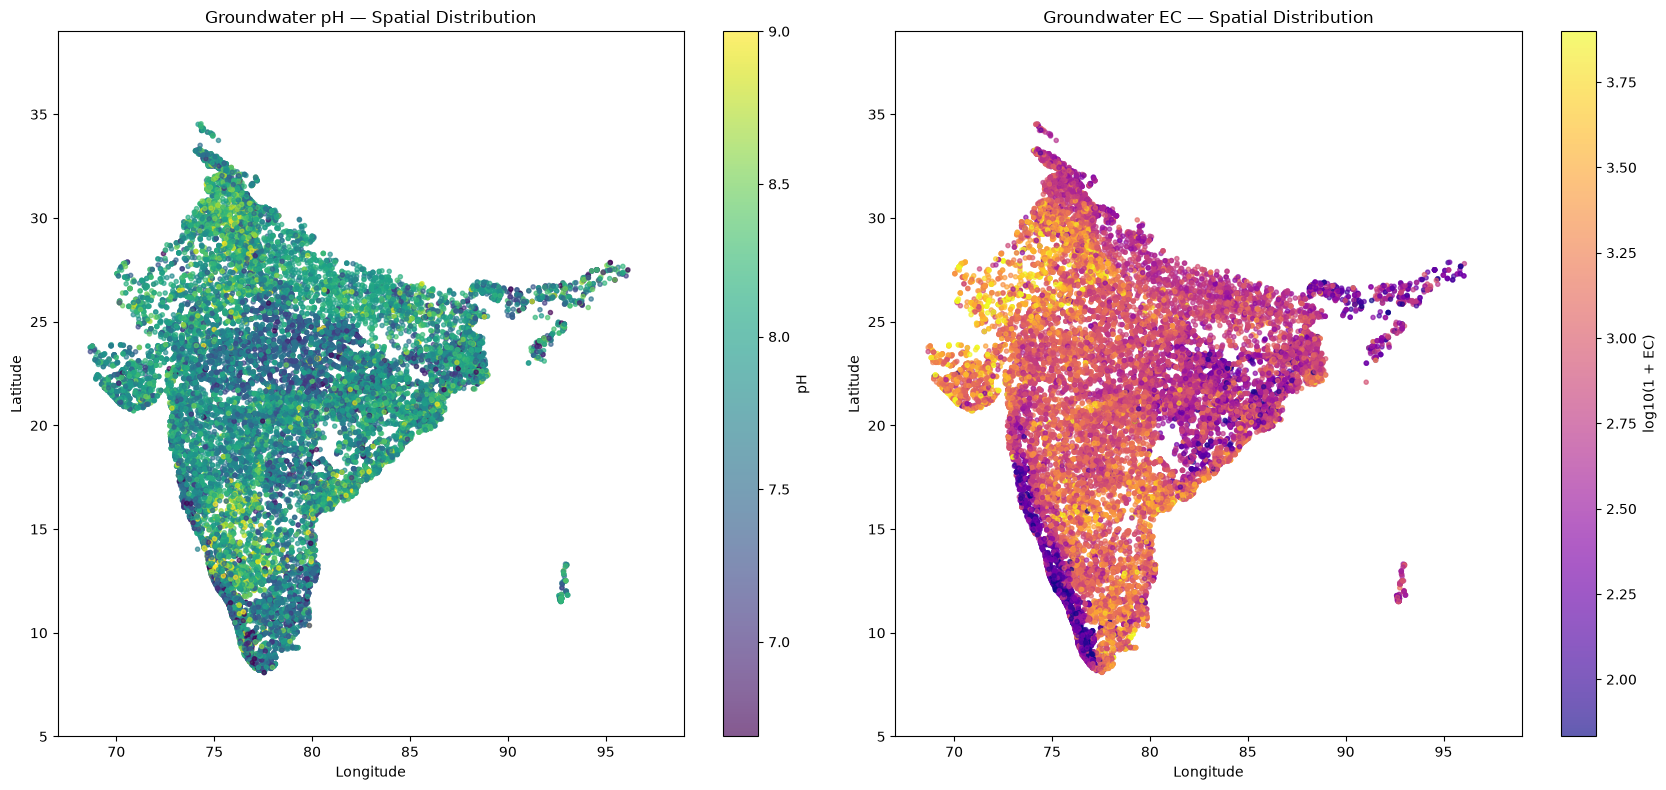

pH observations plotted: 25000
EC observations plotted: 25000


In [13]:
geo_plot_df = eda_df[
    ["Latitude", "Longitude",
     "Potential of Hydrogen (pH)",
     "Electric Conductivity (μS/cm)"]
].dropna(subset=["Latitude", "Longitude"]).copy()

geo_plot_df = geo_plot_df[
    geo_plot_df["Latitude"].between(5, 39)
    & geo_plot_df["Longitude"].between(67, 99)
]

ph_geo = geo_plot_df[
    geo_plot_df["Potential of Hydrogen (pH)"].between(0.000001, 14)
].copy()

ec_geo = geo_plot_df[
    geo_plot_df["Electric Conductivity (μS/cm)"].ge(0)
].copy()

ph_geo = ph_geo.sample(
    n=min(25000, len(ph_geo)),
    random_state=42
)

ec_geo = ec_geo.sample(
    n=min(25000, len(ec_geo)),
    random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(17, 8))

ph_vmin = ph_geo["Potential of Hydrogen (pH)"].quantile(0.01)
ph_vmax = ph_geo["Potential of Hydrogen (pH)"].quantile(0.99)

scatter1 = axes[0].scatter(
    ph_geo["Longitude"],
    ph_geo["Latitude"],
    c=ph_geo["Potential of Hydrogen (pH)"],
    cmap="viridis",
    vmin=ph_vmin,
    vmax=ph_vmax,
    s=9,
    alpha=0.65
)

axes[0].set_title("Groundwater pH — Spatial Distribution")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].set_xlim(67, 99)
axes[0].set_ylim(5, 39)
plt.colorbar(scatter1, ax=axes[0], label="pH")

ec_geo["_log_ec"] = np.log10(
    1 + ec_geo["Electric Conductivity (μS/cm)"]
)

ec_vmin = ec_geo["_log_ec"].quantile(0.01)
ec_vmax = ec_geo["_log_ec"].quantile(0.99)

scatter2 = axes[1].scatter(
    ec_geo["Longitude"],
    ec_geo["Latitude"],
    c=ec_geo["_log_ec"],
    cmap="plasma",
    vmin=ec_vmin,
    vmax=ec_vmax,
    s=9,
    alpha=0.65
)

axes[1].set_title("Groundwater EC — Spatial Distribution")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].set_xlim(67, 99)
axes[1].set_ylim(5, 39)
plt.colorbar(
    scatter2,
    ax=axes[1],
    label="log10(1 + EC)"
)

plt.tight_layout()

plt.savefig(
    EDA_DIR / "08_nationwide_spatial_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("pH observations plotted:", len(ph_geo))
print("EC observations plotted:", len(ec_geo))

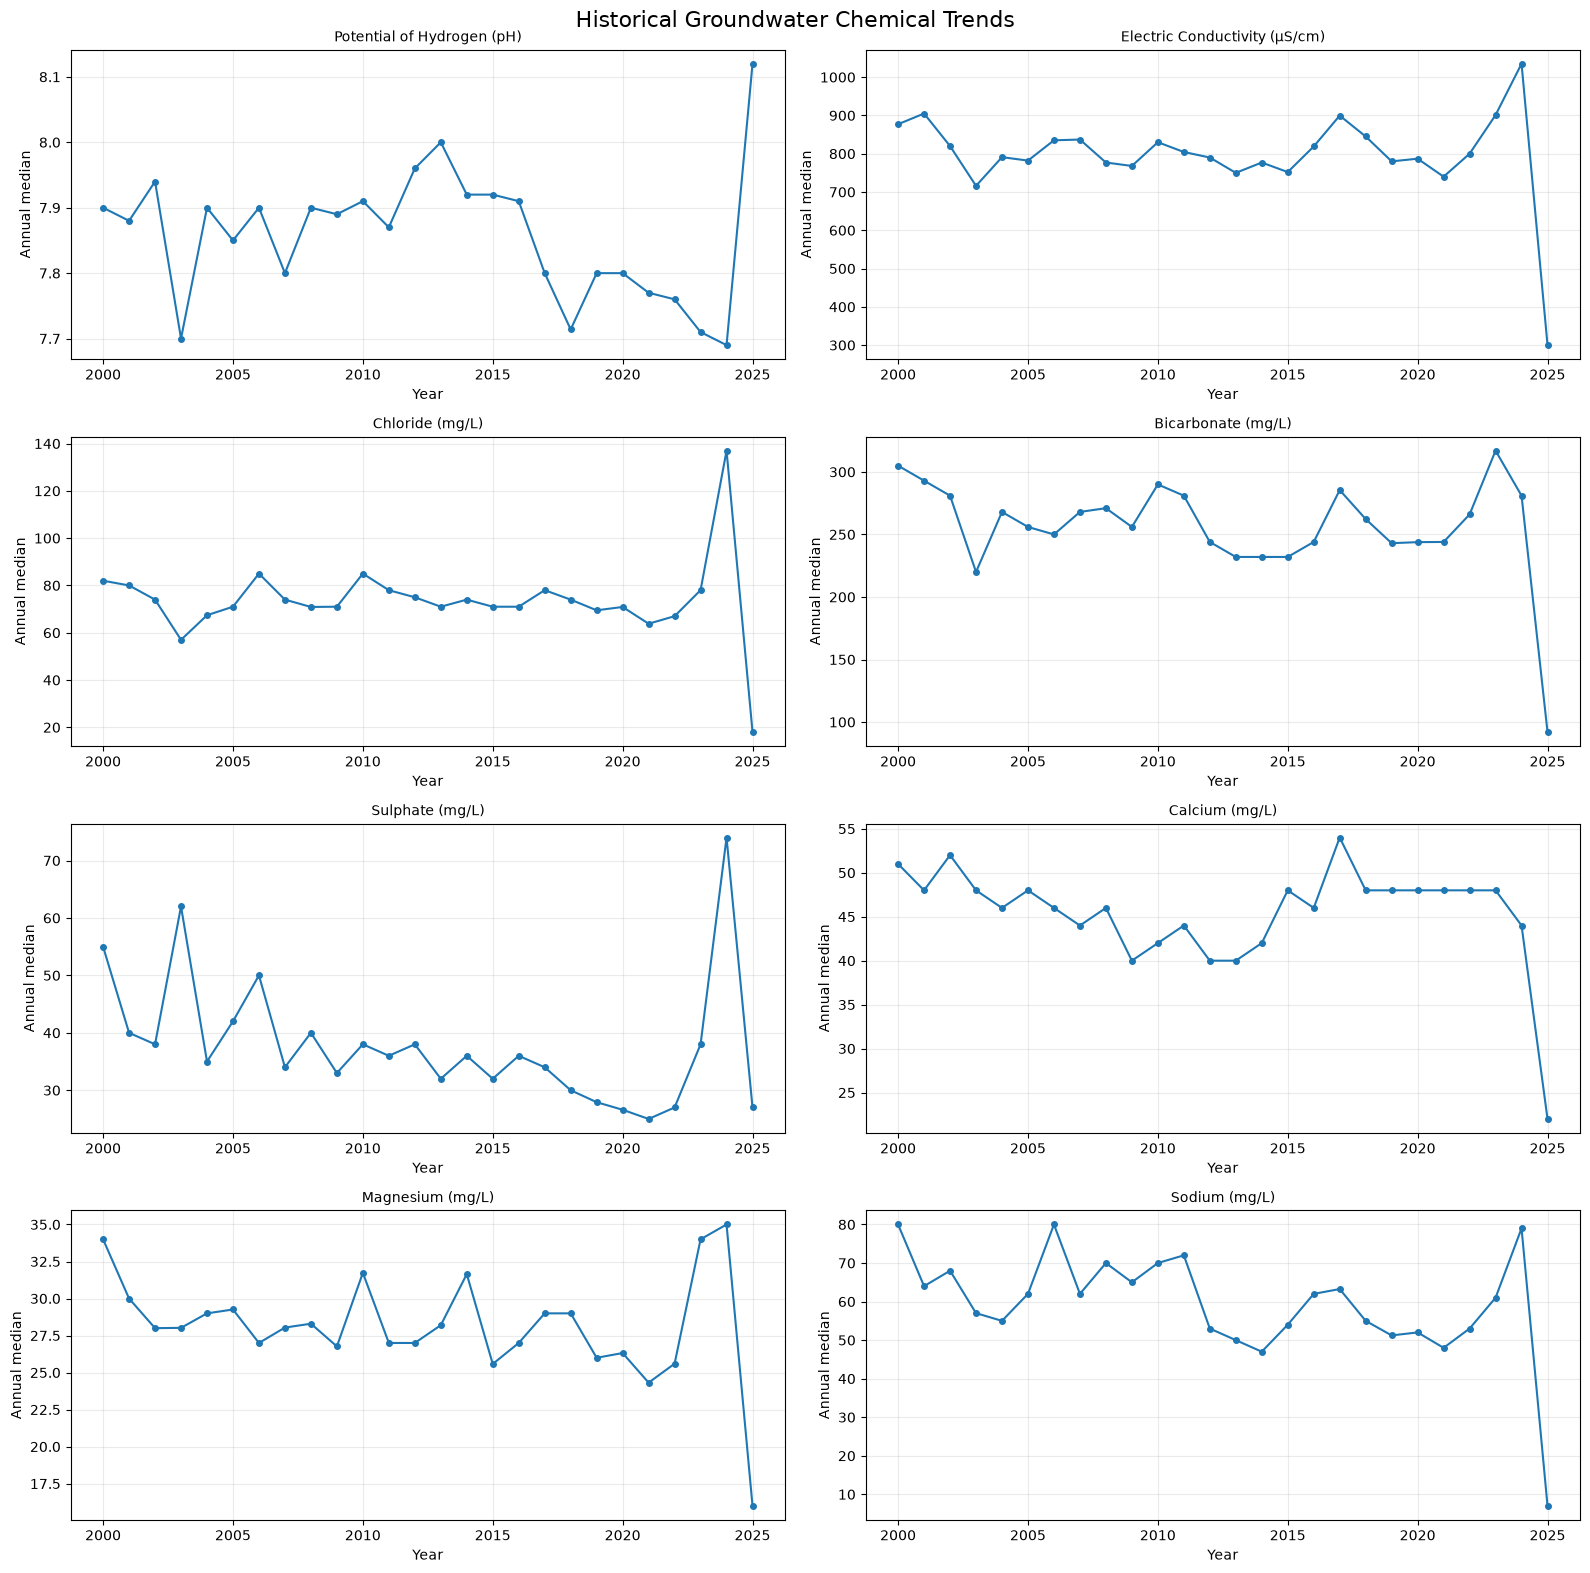

ANNUAL MEDIAN AND SAMPLE COUNTS


,_year,Median,Available,Parameter
0,2000,7.90,5505,Potential of Hydrogen (pH)
1,2001,7.88,4824,Potential of Hydrogen (pH)
2,2002,7.94,6321,Potential of Hydrogen (pH)
3,2003,7.70,1377,Potential of Hydrogen (pH)
4,2004,7.90,6770,Potential of Hydrogen (pH)
...,...,...,...,...
203,2021,48.00,5992,Sodium (mg/L)
204,2022,53.00,5146,Sodium (mg/L)
205,2023,61.00,2503,Sodium (mg/L)
206,2024,79.00,15,Sodium (mg/L)


In [14]:
trend_parameters = [
    "Potential of Hydrogen (pH)",
    "Electric Conductivity (μS/cm)",
    "Chloride (mg/L)",
    "Bicarbonate (mg/L)",
    "Sulphate (mg/L)",
    "Calcium (mg/L)",
    "Magnesium (mg/L)",
    "Sodium (mg/L)"
]

trend_df = eda_df[
    ["_year"] + trend_parameters
].copy()

# Apply the same basic screening used in descriptive analysis.
for column in trend_parameters:

    if column == "Potential of Hydrogen (pH)":
        trend_df.loc[
            ~trend_df[column].between(0.000001, 14),
            column
        ] = np.nan

    else:
        trend_df.loc[
            trend_df[column] < 0,
            column
        ] = np.nan

annual_trends = []

for column in trend_parameters:

    yearly = (
        trend_df.groupby("_year")[column]
        .agg(
            Median="median",
            Available="count"
        )
        .reset_index()
    )

    yearly["Parameter"] = column
    annual_trends.append(yearly)

annual_trends_df = pd.concat(
    annual_trends,
    ignore_index=True
)

fig, axes = plt.subplots(4, 2, figsize=(16, 16))

for column, ax in zip(
    trend_parameters,
    axes.flatten()
):

    subset = annual_trends_df[
        annual_trends_df["Parameter"] == column
    ]

    ax.plot(
        subset["_year"],
        subset["Median"],
        marker="o",
        markersize=4
    )

    ax.set_title(column, fontsize=10)
    ax.set_xlabel("Year")
    ax.set_ylabel("Annual median")
    ax.grid(alpha=0.25)

plt.suptitle(
    "Historical Groundwater Chemical Trends",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    EDA_DIR / "09_annual_chemical_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ANNUAL MEDIAN AND SAMPLE COUNTS")
display(
    annual_trends_df.round(2)
)

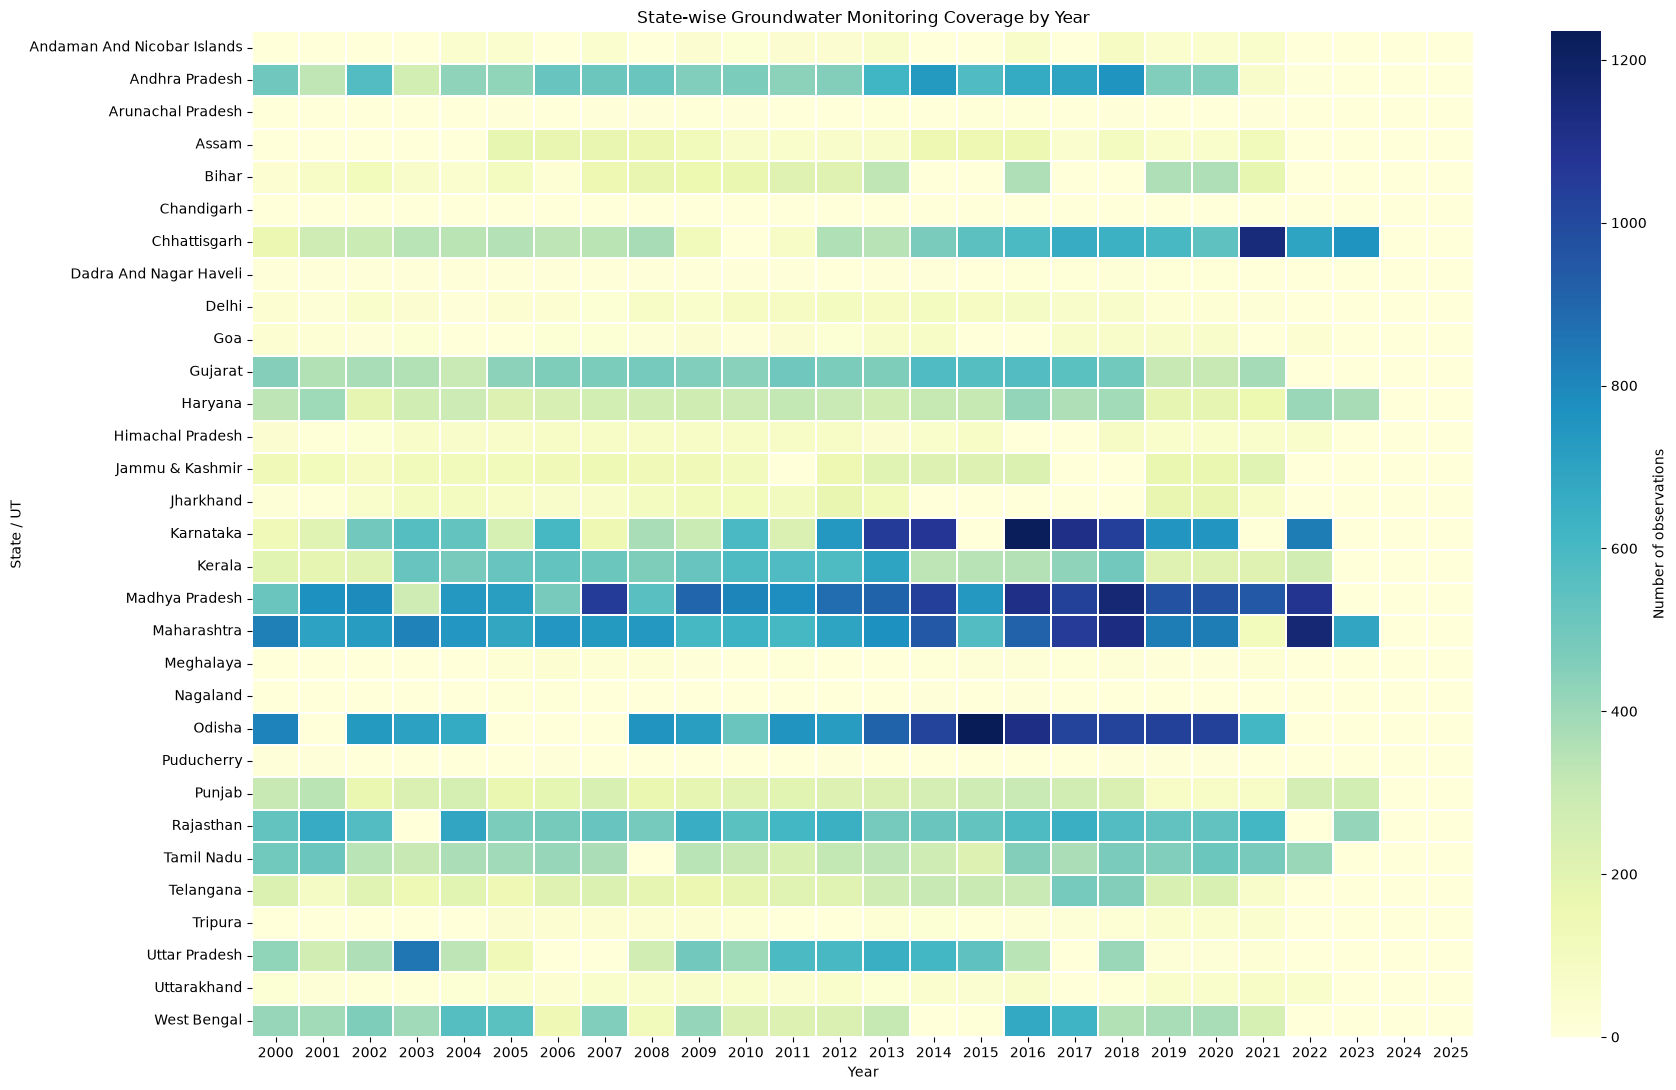

MONTH-WISE SAMPLING DISTRIBUTION


,Month,Records
0,1,1
1,2,50
2,3,2
3,4,277
4,5,170967
5,6,2297
6,7,36
7,8,243
8,9,4
9,10,4



STATE-YEAR COVERAGE MATRIX
States: 31
Years: 26
Total observations: 174635


In [15]:
state_year_counts = (
    eda_df.pivot_table(
        index="State",
        columns="_year",
        values="_record_id",
        aggfunc="count",
        fill_value=0
    )
)

plt.figure(figsize=(18, 11))

sns.heatmap(
    state_year_counts,
    cmap="YlGnBu",
    linewidths=0.1,
    cbar_kws={
        "label": "Number of observations"
    }
)

plt.title(
    "State-wise Groundwater Monitoring Coverage by Year"
)
plt.xlabel("Year")
plt.ylabel("State / UT")

plt.tight_layout()

plt.savefig(
    EDA_DIR / "10_state_year_sampling_coverage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Monthly sampling distribution
monthly_counts = (
    eda_df["_parsed_date"]
    .dt.month
    .value_counts()
    .sort_index()
)

monthly_summary = pd.DataFrame({
    "Month": monthly_counts.index,
    "Records": monthly_counts.values
})

print("MONTH-WISE SAMPLING DISTRIBUTION")
display(monthly_summary)

print("\nSTATE-YEAR COVERAGE MATRIX")
print("States:", len(state_year_counts))
print("Years:", len(state_year_counts.columns))
print("Total observations:", state_year_counts.values.sum())

In [16]:
# Annual sampling diagnostics
annual_sampling_summary = (
    eda_df.groupby("_year")
    .agg(
        Records=("_year", "size"),
        States=("State", "nunique"),
        Station_Identities=("_provisional_station_id", "nunique")
    )
    .reset_index()
)

annual_sampling_summary["Record_Share_%"] = (
    annual_sampling_summary["Records"]
    / len(eda_df) * 100
).round(2)

# Monthly sampling diagnostics
monthly_sampling_summary = (
    eda_df["_parsed_date"]
    .dt.month
    .value_counts()
    .sort_index()
    .rename_axis("Month")
    .reset_index(name="Records")
)

monthly_sampling_summary["Share_%"] = (
    monthly_sampling_summary["Records"]
    / len(eda_df) * 100
).round(2)

# State-level parameter availability
state_parameter_support = (
    eda_df.groupby("State")[analysis_parameters]
    .count()
    .reset_index()
)

# Strongest observed parameter associations
correlation_pairs = []

for i, parameter_a in enumerate(spearman_corr.columns):

    for parameter_b in spearman_corr.columns[i + 1:]:

        correlation_value = spearman_corr.loc[
            parameter_a, parameter_b
        ]

        paired_count = pair_counts.loc[
            parameter_a, parameter_b
        ]

        if pd.notna(correlation_value):

            correlation_pairs.append({
                "Parameter_A": parameter_a,
                "Parameter_B": parameter_b,
                "Spearman_Rho": correlation_value,
                "Paired_Observations": paired_count
            })

correlation_pairs_df = pd.DataFrame(
    correlation_pairs
).sort_values(
    "Spearman_Rho",
    key=lambda x: x.abs(),
    ascending=False
)

print("ANNUAL SAMPLING DIAGNOSTICS")
display(annual_sampling_summary)

print("\nMONTHLY SAMPLING DIAGNOSTICS")
display(monthly_sampling_summary)

print("\nSTRONGEST CHEMICAL ASSOCIATIONS")
display(correlation_pairs_df.head(15))

ANNUAL SAMPLING DIAGNOSTICS


,_year,Records,States,Station_Identities,Record_Share_%
0,2000,6645,27,6633,3.81
1,2001,5747,23,5731,3.29
2,2002,6862,24,6845,3.93
3,2003,6486,25,6475,3.71
4,2004,7332,24,7323,4.20
5,2005,6215,30,6209,3.56
6,2006,6022,28,6015,3.45
7,2007,6662,28,6656,3.81
8,2008,6649,27,6635,3.81
9,2009,7440,30,7434,4.26



MONTHLY SAMPLING DIAGNOSTICS


,Month,Records,Share_%
0,1,1,0.00
1,2,50,0.03
2,3,2,0.00
3,4,277,0.16
4,5,170967,97.90
5,6,2297,1.32
6,7,36,0.02
7,8,243,0.14
8,9,4,0.00
9,10,4,0.00



STRONGEST CHEMICAL ASSOCIATIONS


,Parameter_A,Parameter_B,Spearman_Rho,Paired_Observations
44,Bicarbonate (mg/L),Total Alkalinity (mg/L as CaCO3),0.903134,79899
12,Electric Conductivity (μS/cm),Chloride (mg/L),0.881295,161997
57,Magnesium (mg/L),Total Hardness (mgCaCO3/L),0.871214,142470
17,Electric Conductivity (μS/cm),Sodium (mg/L),0.865764,143439
18,Electric Conductivity (μS/cm),Total Hardness (mgCaCO3/L),0.842982,144385
34,Chloride (mg/L),Sodium (mg/L),0.802411,142685
53,Calcium (mg/L),Total Hardness (mgCaCO3/L),0.795282,141885
16,Electric Conductivity (μS/cm),Magnesium (mg/L),0.792595,150378
14,Electric Conductivity (μS/cm),Sulphate (mg/L),0.754692,126297
35,Chloride (mg/L),Total Hardness (mgCaCO3/L),0.731776,141105


In [17]:
eda_outputs = {
    "parameter_availability.csv": availability_summary,
    "chemical_descriptive_statistics.csv": descriptive_stats_df,
    "spearman_correlation_matrix.csv": spearman_corr,
    "spearman_pair_observation_counts.csv": pair_counts,
    "chemical_relationship_summary.csv": relationship_summary_df,
    "strongest_chemical_correlations.csv": correlation_pairs_df,
    "statewise_chemical_medians.csv": state_medians,
    "statewise_chemical_sample_counts.csv": state_counts,
    "state_parameter_support.csv": state_parameter_support,
    "annual_chemical_trends.csv": annual_trends_df,
    "annual_sampling_diagnostics.csv": annual_sampling_summary,
    "monthly_sampling_distribution.csv": monthly_sampling_summary,
    "state_year_sampling_coverage.csv": state_year_counts
}

for filename, dataframe in eda_outputs.items():

    dataframe.to_csv(
        EDA_DIR / filename,
        index=True if dataframe.index.name or dataframe.index.dtype == object else False,
        encoding="utf-8-sig"
    )

print("EDA TABLE EXPORT COMPLETED")
print("Tables exported:", len(eda_outputs))

for filename in eda_outputs:
    print("✓", filename)

EDA TABLE EXPORT COMPLETED
Tables exported: 13
✓ parameter_availability.csv
✓ chemical_descriptive_statistics.csv
✓ spearman_correlation_matrix.csv
✓ spearman_pair_observation_counts.csv
✓ chemical_relationship_summary.csv
✓ strongest_chemical_correlations.csv
✓ statewise_chemical_medians.csv
✓ statewise_chemical_sample_counts.csv
✓ state_parameter_support.csv
✓ annual_chemical_trends.csv
✓ annual_sampling_diagnostics.csv
✓ monthly_sampling_distribution.csv
✓ state_year_sampling_coverage.csv


In [18]:
expected_charts = [
    "01_chemical_parameter_availability.png",
    "02_initial_chemical_distributions.png",
    "03_screened_chemical_distributions.png",
    "04_spearman_correlation_heatmap.png",
    "05_chemical_relationships.png",
    "08_nationwide_spatial_distribution.png",
    "09_annual_chemical_trends.png",
    "10_state_year_sampling_coverage.png"
]

print("EDA VISUALIZATION VERIFICATION")
print("=" * 50)

chart_results = []

for filename in expected_charts:

    path = EDA_DIR / filename

    chart_results.append({
        "Chart": filename,
        "Exists": path.exists(),
        "Size_KB": round(path.stat().st_size / 1024, 2)
        if path.exists() else 0
    })

chart_verification_df = pd.DataFrame(chart_results)

display(chart_verification_df)

print("Charts available:",
      chart_verification_df["Exists"].sum(),
      "/",
      len(expected_charts))

EDA VISUALIZATION VERIFICATION


,Chart,Exists,Size_KB
0,01_chemical_parameter_availability.png,True,279.87
1,02_initial_chemical_distributions.png,True,391.81
2,03_screened_chemical_distributions.png,True,462.23
3,04_spearman_correlation_heatmap.png,True,629.66
4,05_chemical_relationships.png,True,1829.03
5,08_nationwide_spatial_distribution.png,True,3744.11
6,09_annual_chemical_trends.png,True,815.86
7,10_state_year_sampling_coverage.png,True,317.80


Charts available: 8 / 8


In [19]:
print("PHASE 4 — FINAL EDA VALIDATION")
print("=" * 60)

print("\nDATASET")
print("Total observations:", len(eda_df))
print("Valid dates:", eda_df["_parsed_date"].notna().sum())
print("Chemical parameters:", len(chemical_columns))
print("States and UTs:", eda_df["State"].nunique())

print("\nTEMPORAL COVERAGE")
print("Annual summary records:",
      annual_sampling_summary["Records"].sum())

print("Monthly summary records:",
      monthly_sampling_summary["Records"].sum())

print("\nSAMPLING DISTRIBUTION")
print("May observations:",
      monthly_sampling_summary.loc[
          monthly_sampling_summary["Month"] == 5,
          "Records"
      ].sum())

print("\nANALYSIS OUTPUTS")
print("Tables:", len(eda_outputs))
print("Charts available:",
      chart_verification_df["Exists"].sum())

print("\nFINAL ASSERTIONS")

assert len(eda_df) == 174635
assert eda_df["_parsed_date"].notna().all()
assert annual_sampling_summary["Records"].sum() == len(eda_df)
assert monthly_sampling_summary["Records"].sum() == len(eda_df)
assert chart_verification_df["Exists"].all()

print("All EDA validation checks passed.")
print("\nPHASE 4 — EXPLORATORY DATA ANALYSIS COMPLETED")

PHASE 4 — FINAL EDA VALIDATION

DATASET
Total observations: 174635
Valid dates: 174635
Chemical parameters: 27
States and UTs: 31

TEMPORAL COVERAGE
Annual summary records: 174635
Monthly summary records: 174635

SAMPLING DISTRIBUTION
May observations: 170967

ANALYSIS OUTPUTS
Tables: 13
Charts available: 8

FINAL ASSERTIONS
All EDA validation checks passed.

PHASE 4 — EXPLORATORY DATA ANALYSIS COMPLETED



# PHASE 4 — EXPLORATORY DATA ANALYSIS
## FINAL COMPLETION REPORT

**Project:** Borewell Sentinel India  
**Phase:** 4 — Exploratory Data Analysis  
**Status:** COMPLETED  
**Input:** groundwater_master_processed.csv  
**Total observations:** 174,635

---

## 1. Phase Objective

The purpose of this phase was to investigate the geographical, temporal and chemical characteristics of the integrated CGWB groundwater dataset.

The analysis covered data availability, descriptive statistics, chemical distributions, parameter correlations, spatial patterns and historical sampling behaviour.

No modifications were made to the processed master dataset during EDA.

## 2. Dataset Overview

- Total observations: 174,635
- Geographic coverage: 31 states and UTs
- Distinct district labels: 596
- Chemical parameters investigated: 27
- Historical coverage: 25 May 2000 – 8 May 2025

All 174,635 observations were successfully accounted for in the corrected annual and monthly summaries.

## 3. Chemical Parameter Availability

The most extensively observed parameters were:

| Parameter | Availability |
|---|---:|
| Electrical Conductivity | 99.08% |
| pH | 93.18% |
| Chloride | 92.78% |
| Magnesium | 86.14% |
| Calcium | 85.81% |
| Bicarbonate | 84.27% |
| Total Hardness | 82.69% |
| Sodium | 82.15% |

Nitrate, fluoride and potassium had no available observations.

Trace-metal measurements were particularly sparse.

These findings will guide subsequent feature selection and prediction-target feasibility analysis.

## 4. Chemical Distribution Findings

The descriptive analysis revealed:

- pH measurements are concentrated around 7–8.
- Electrical conductivity and major-ion measurements exhibit varying degrees of right-skewness.
- Several parameters contain substantial zero-value concentrations.
- Mean values are influenced by extreme observations.
- Medians and percentiles provide useful complementary descriptions of the chemical distributions.

Logarithmic transformations were used for visualization of selected concentration measurements. These transformations did not overwrite the original values.

## 5. Chemical Relationships

Spearman correlation analysis identified several strong positive relationships.

| Parameter Pair | Spearman Correlation |
|---|---:|
| Bicarbonate – Total Alkalinity | 0.903 |
| EC – Chloride | 0.880 |
| Total Hardness – Magnesium | 0.871 |
| EC – Sodium | 0.870 |
| Total Hardness – Calcium | 0.795 |
| EC – Total Hardness | 0.840 |

The number of paired observations varied between parameter combinations.

These relationships provide useful insights for future feature engineering and prediction-model design.

Correlations indicate statistical association, not causation.

## 6. Geographical Findings

Spatial visualizations were generated using the available monitoring coordinates.

The maps revealed the nationwide distribution of recorded observations and geographic variation in pH and electrical conductivity.

State-wise median comparisons demonstrated substantial differences in selected groundwater parameters.

However, state-level comparisons are affected by varying observation counts, geographical coverage and sampling composition.

They must not be treated as definitive contamination rankings.

## 7. Temporal Findings

Annual median trends were calculated for eight major chemical parameters.

The analysis revealed year-to-year fluctuations in pH, electrical conductivity and major-ion concentrations.

However, annual sampling coverage was uneven.

| Year | Records | States |
|---|---:|---:|
| 2020 | 8,109 | 31 |
| 2021 | 5,994 | 29 |
| 2022 | 5,264 | 16 |
| 2023 | 2,522 | 12 |
| 2024 | 15 | 6 |
| 2025 | 1 | 1 |

The 2024 and 2025 observations are insufficient to support reliable nationwide temporal conclusions.

Annual comparisons also reflect changes in sampling coverage and the composition of monitored stations.

## 8. Sampling Seasonality

The monthly distribution revealed a strong concentration of observations in May.

- May: 170,967 observations.
- Total observations: 174,635.
- May share: approximately 97.90%.

This limits the ability to conduct meaningful comparisons between months and seasons.

Future temporal analysis must account for the strong sampling-season concentration.

## 9. EDA Outputs

All analytical tables and visualization files are stored in:

`reports/eda/`

The outputs include:

- Chemical parameter availability summary.
- Descriptive statistical summaries.
- Spearman correlation matrix.
- Paired observation counts.
- Chemical relationship summaries.
- State-wise chemical medians and sample counts.
- Annual chemical trends.
- Monthly sampling distribution.
- State-year sampling coverage matrix.
- Spatial distribution maps.
- Chemical distribution charts.
- Correlation and relationship visualizations.

## 10. Important Analytical Limitations

The EDA identified several limitations that must inform further modelling:

1. Uneven availability across chemical parameters.
2. Completely unavailable nitrate, fluoride and potassium parameters.
3. Extreme and suspicious recorded values.
4. Large differences in sampling activity between states and years.
5. Limited observations in 2024 and 2025.
6. Sampling heavily concentrated in May.
7. Correlations based on differing numbers of paired observations.
8. Unverified station-location identities and repeated observations.
9. Possible bias from the changing composition of sampled locations.

These limitations must be addressed during feature preparation, model validation and interpretation.

## 11. Phase Conclusion

Phase 4 successfully established a descriptive and exploratory understanding of the CGWB groundwater dataset.

The analysis identified:

- Well-supported chemical parameters.
- Strong relationships among selected chemical measurements.
- Geographical differences in groundwater chemistry.
- Historical variations in annual chemical summaries.
- Significant geographical and temporal sampling imbalances.

These findings establish the analytical foundation for preparing prediction targets, selecting features and engineering model-ready variables.

**PHASE 4 — EXPLORATORY DATA ANALYSIS: COMPLETED**

---

**NEXT PHASE:**

# PHASE 5 — FEATURE ENGINEERING & TARGET PREPARATION
